In [86]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mutual_info_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

%matplotlib inline

In [2]:
# loading the dataset
filepath = os.path.join(os.path.abspath(".."), "data", "course_lead_scoring_2026.csv")
df = pd.read_csv(filepath)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [4]:
# finding columns containing missing values
nulls = df.columns[df.isnull().sum() != 0]
cat = nulls[df[nulls].dtypes == "str"]
dog = nulls[df[nulls].dtypes != "str"]

# filling missing values
df[cat] = df[cat].fillna("NA")
df[dog] = df[dog].fillna(0.0)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   str    
 1   industry                  5000 non-null   str    
 2   employment_status         5000 non-null   str    
 3   location                  5000 non-null   str    
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [5]:
# describing dataframes mathematically/statistically 
df.describe()

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,50508.661000,2.089400,4.472600,0.491304,0.576600
std,24927.396949,1.188987,2.435906,0.202969,0.494147
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35082.750000,1.000000,3.000000,0.350000,0.000000
50%,52613.000000,2.000000,4.000000,0.490000,1.000000
75%,69752.750000,3.000000,6.000000,0.630000,1.000000
max,109886.000000,6.000000,13.000000,0.990000,1.000000


In [6]:
df.industry.mode()

0    technology
Name: industry, dtype: str

converted
1    2883
0    2117
Name: count, dtype: int64

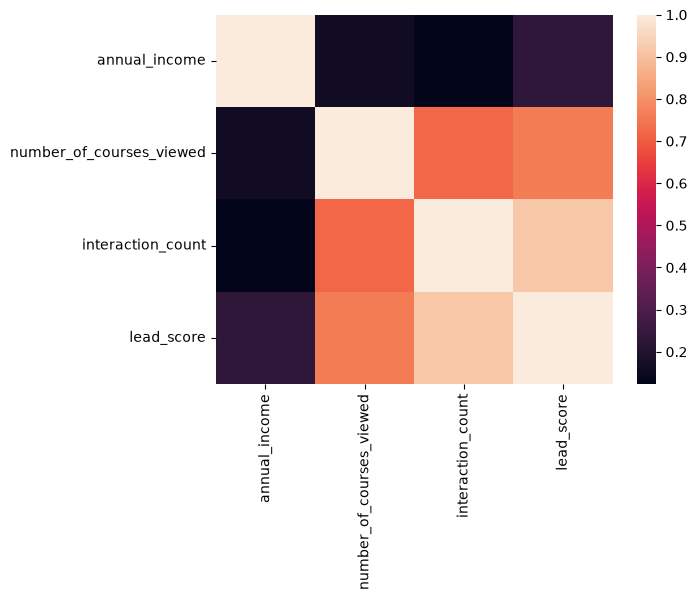

In [57]:
# annual income vs interaction_count max -ve correlation coefficient
features = df.drop(columns=["converted"])
y = df.converted
sns.heatmap(features.corr(numeric_only=True));
# balanced values
y.value_counts()

In [41]:
# maybe for converting to numerical i.e. one-hot-encoding
features[features.columns[features.dtypes == "str"]].nunique()

lead_source          6
industry             7
employment_status    5
location             6
dtype: int64

In [51]:
help(sklearn.metrics.mutual_info_score)

Help on function mutual_info_score in module sklearn.metrics.cluster._supervised:

mutual_info_score(labels_true, labels_pred, *, contingency=None)
    Mutual Information between two clusterings.

    The Mutual Information is a measure of the similarity between two labels
    of the same data. Where :math:`|U_i|` is the number of the samples
    in cluster :math:`U_i` and :math:`|V_j|` is the number of the
    samples in cluster :math:`V_j`, the Mutual Information
    between clusterings :math:`U` and :math:`V` is given as:

    .. math::

        MI(U,V)=\sum_{i=1}^{|U|} \sum_{j=1}^{|V|} \frac{|U_i\cap V_j|}{N}
        \log\frac{N|U_i \cap V_j|}{|U_i||V_j|}

    This metric is independent of the absolute values of the labels:
    a permutation of the class or cluster label values won't change the
    score value in any way.

    This metric is furthermore symmetric: switching :math:`U` (i.e
    ``label_true``) with :math:`V` (i.e. ``label_pred``) will return the
    same score value.

In [91]:
# train, test, split
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=42)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [92]:
y_train = df_train.converted
df_train = df_train.drop(columns=["converted"])
df_train.columns, y_train

(Index(['lead_source', 'industry', 'employment_status', 'location',
        'annual_income', 'number_of_courses_viewed', 'interaction_count',
        'lead_score'],
       dtype='str'),
 0       1
 1       0
 2       1
 3       0
 4       1
        ..
 2995    0
 2996    1
 2997    1
 2998    0
 2999    0
 Name: converted, Length: 3000, dtype: int64)

In [93]:
# mutual information score
cat = df_train.columns[df_train.dtypes == "str"]
mi = df_train[cat].apply(lambda x: round(mutual_info_score(x, y_train), 2)).sort_values(ascending=True)
mi

industry             0.00
location             0.00
employment_status    0.02
lead_source          0.03
dtype: float64

In [94]:
# one hot encoding...
dv = DictVectorizer(sparse=False)
dicts = df_train.to_dict(orient="records")
X_train = dv.fit_transform(dicts)
X_train.shape
y_train = y_train.values
y_train

array([1, 0, 1, ..., 1, 0, 0], shape=(3000,))

In [95]:
y_val = df_val.converted
df_val = df_val.drop(columns=["converted"])
df_val.columns, y_val

(Index(['lead_source', 'industry', 'employment_status', 'location',
        'annual_income', 'number_of_courses_viewed', 'interaction_count',
        'lead_score'],
       dtype='str'),
 0      1
 1      1
 2      0
 3      1
 4      0
       ..
 995    1
 996    1
 997    0
 998    0
 999    1
 Name: converted, Length: 1000, dtype: int64)

In [96]:
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The 

In [100]:
model.intercept_[0].round(3)

np.float64(-0.011)

In [101]:
model.coef_[0].round(3)

array([-0.   , -0.001,  0.007, -0.003, -0.008, -0.006, -0.   , -0.003,
       -0.001, -0.002, -0.002, -0.002, -0.001,  0.137,  0.011,  0.   ,
       -0.009,  0.007, -0.014,  0.009, -0.004,  0.   , -0.002, -0.002,
       -0.001, -0.003, -0.004,  0.054])

In [105]:
val_dicts = df_val.to_dict(orient="records")
X_val = dv.transform(val_dicts)
X_val.shape, y_val

((1000, 28),
 0      1
 1      1
 2      0
 3      1
 4      0
       ..
 995    1
 996    1
 997    0
 998    0
 999    1
 Name: converted, Length: 1000, dtype: int64)

In [106]:
y_val = y_val.values
y_val

array([1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1,

In [112]:
y_pred = model.predict_proba(X_val)[:, 1]
something = y_pred >= 0.5
something.shape, something.sum()

((1000,), np.int64(874))

In [126]:
original_accuracy = (y_val == something).mean()
original_accuracy.round(2), original_accuracy

(np.float64(0.64), np.float64(0.645))

In [129]:
for column in ["lead_source", "number_of_courses_viewed", "interaction_count"]:
    print(f"eliminated {column}")
    nothing = df_train.drop(columns=[column])
    dv = DictVectorizer(sparse=False)
    X_train_nothing = dv.fit_transform(nothing.to_dict(orient="records"))
    model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
    model.fit(X_train_nothing, y_train)
    val_nothing = df_val.drop(columns=[column])
    X_val_nothing = dv.transform(val_nothing.to_dict(orient="records"))
    y_pred_nothing = model.predict_proba(X_val_nothing)[:, 1]
    something_nothing = (y_pred_nothing >= 0.5)
    accuracy = (y_val == something_nothing).mean()
    diff = original_accuracy - accuracy
    print(f"diff: {diff}")
    print("----------------------------------------------------------------------------------")

eliminated lead_source
diff: 0.0030000000000000027
----------------------------------------------------------------------------------
eliminated number_of_courses_viewed
diff: 0.0020000000000000018
----------------------------------------------------------------------------------
eliminated interaction_count
diff: 0.04400000000000004
----------------------------------------------------------------------------------


In [133]:
# regularized logistic Regression
for c in [0.000001, 0.00001, 0.0001, 0.001]:
    print(f"c: {c}")
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train.to_dict(orient="records"))
    X_val = dv.transform(df_val.to_dict(orient="records"))
    model = LogisticRegression(solver="liblinear", C=c, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    y_new_pred = model.predict_proba(X_val)[:, 1]
    acc = (y_val == (y_new_pred >= 0.5)).mean().round(3)
    print(f"accuracy: {acc}")
    print("------------------------------------------------------------------------")

c: 1e-06
accuracy: 0.598
------------------------------------------------------------------------
c: 1e-05
accuracy: 0.598
------------------------------------------------------------------------
c: 0.0001
accuracy: 0.613
------------------------------------------------------------------------
c: 0.001
accuracy: 0.645
------------------------------------------------------------------------


In [132]:
df_val.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               1000 non-null   str    
 1   industry                  1000 non-null   str    
 2   employment_status         1000 non-null   str    
 3   location                  1000 non-null   str    
 4   annual_income             1000 non-null   float64
 5   number_of_courses_viewed  1000 non-null   int64  
 6   interaction_count         1000 non-null   int64  
 7   lead_score                1000 non-null   float64
dtypes: float64(2), int64(2), str(4)
memory usage: 62.6 KB
